PDF saved: marginal_distributions_shared_top_legend.pdf


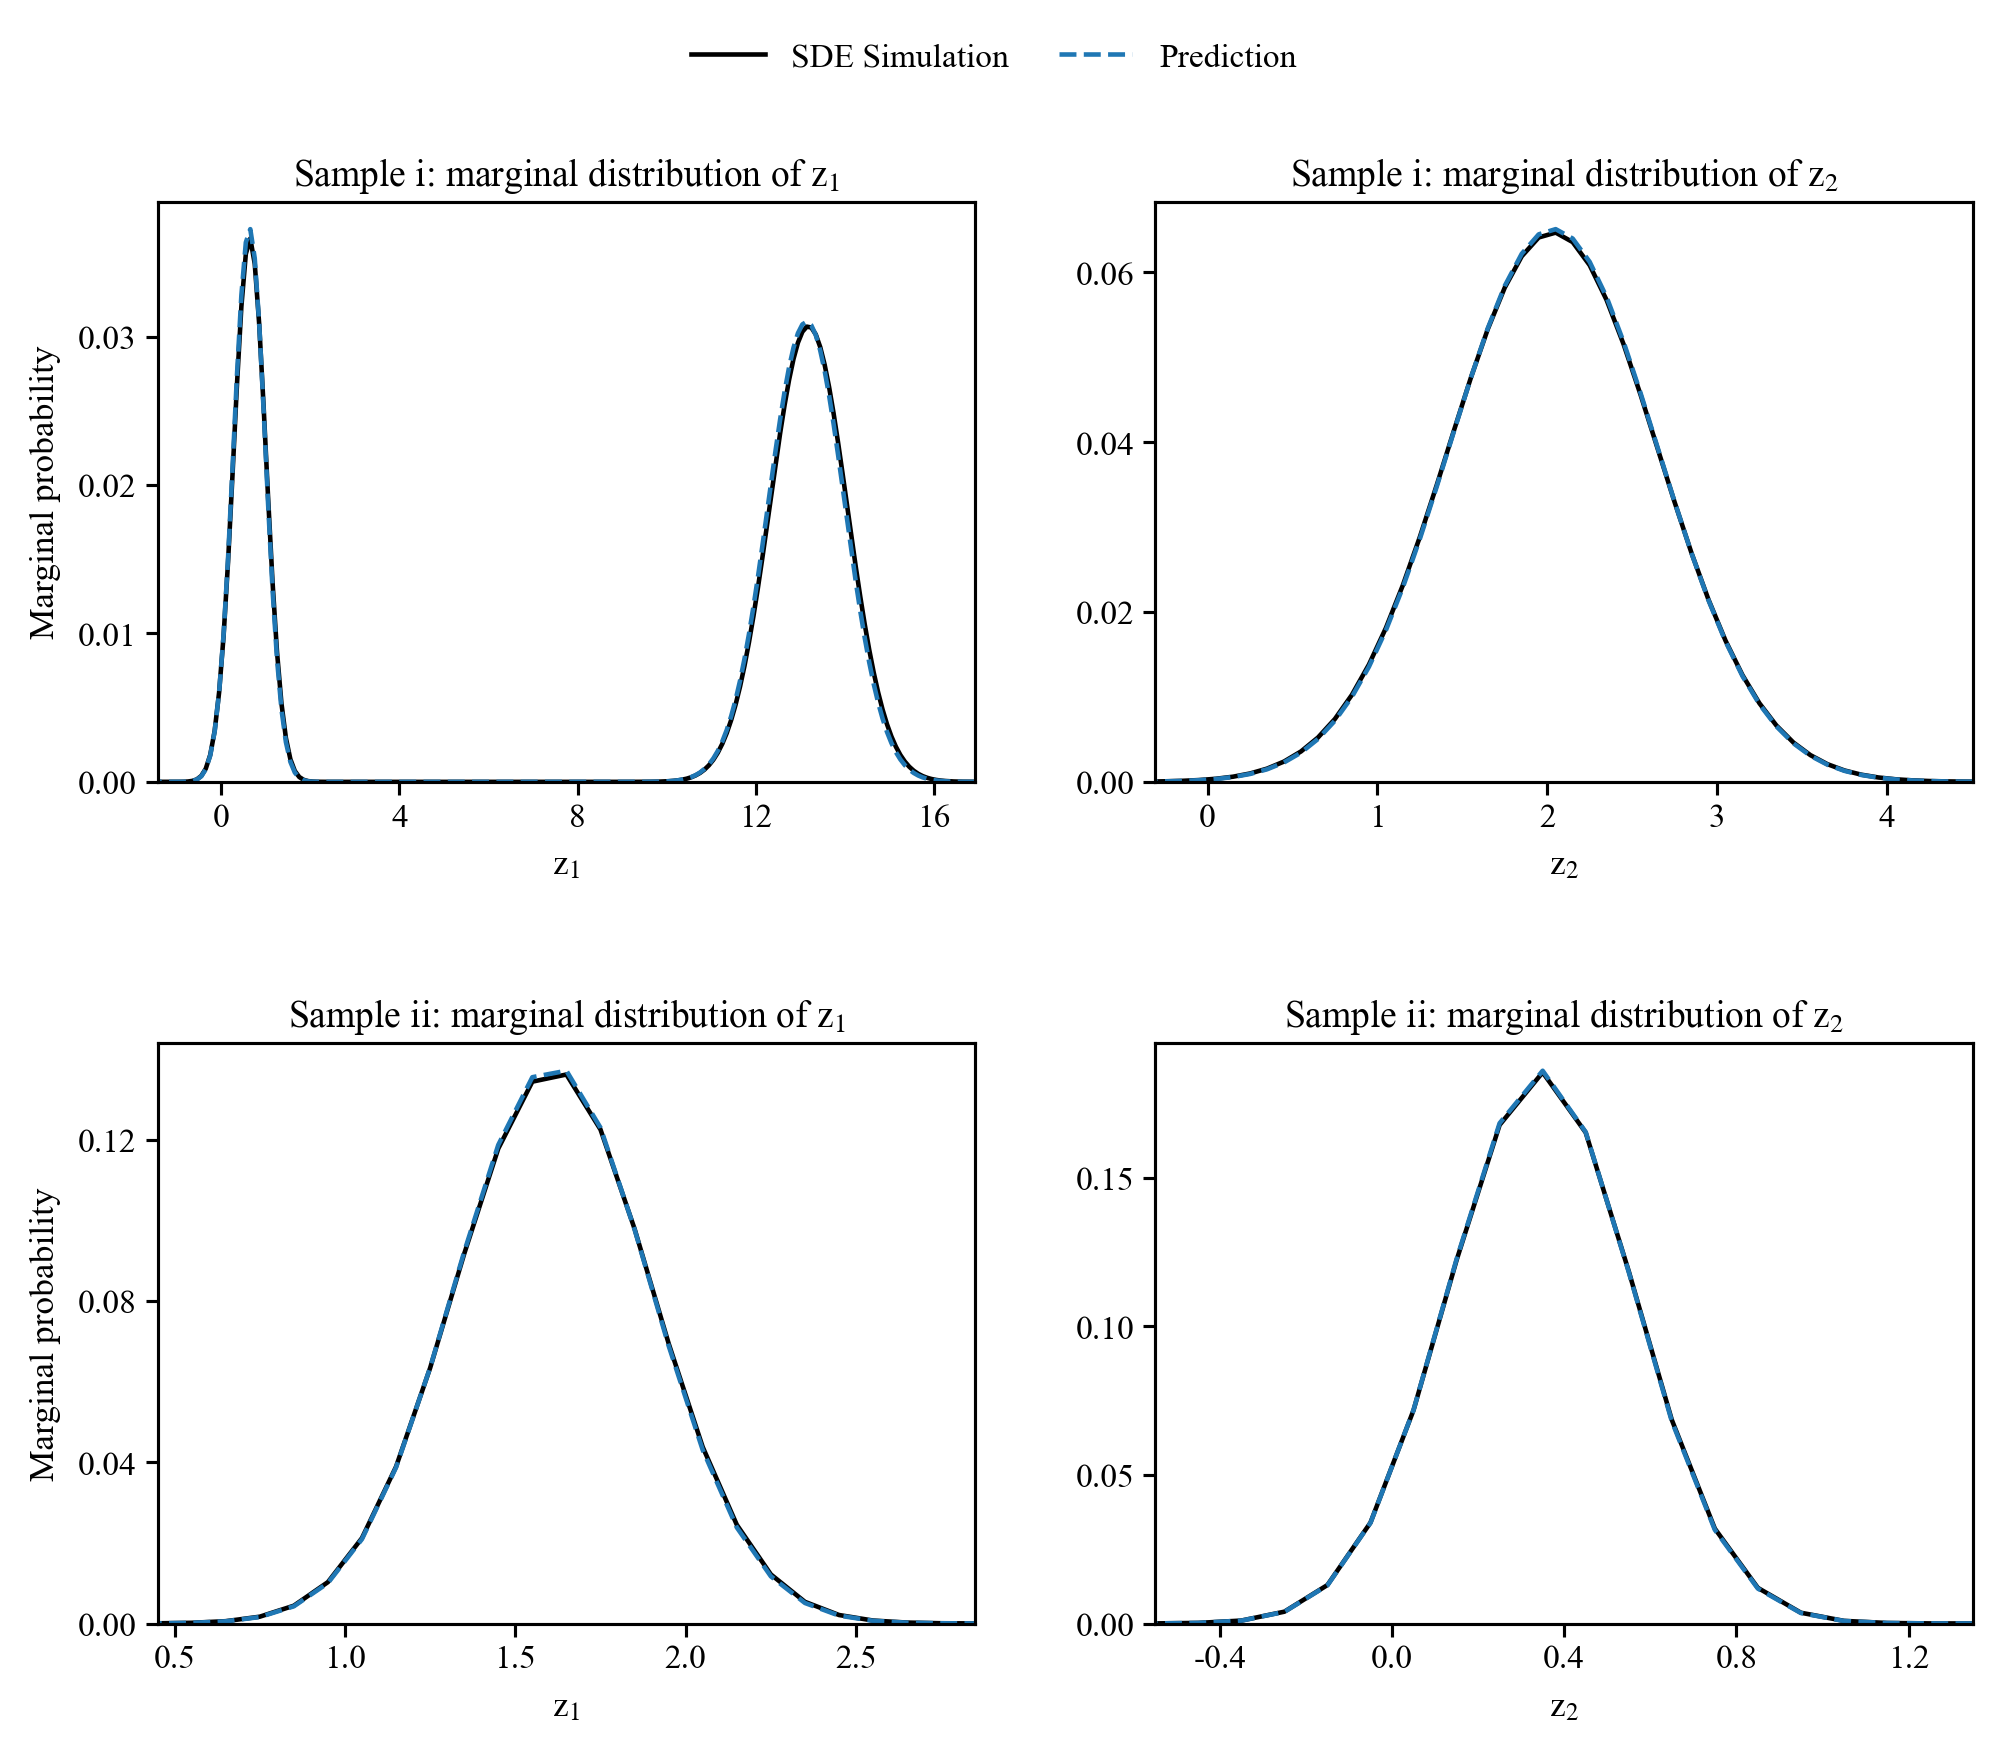

In [13]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from scipy.io import loadmat
from matplotlib.ticker import MaxNLocator


# ===================== 绘图风格 =====================
plt.rcParams.update({
    "font.family": "Times New Roman",
    "mathtext.fontset": "stix",
    "font.size": 8.5,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.75,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})


# ===================== 模型 =====================
class MixtureOfGaussiansModel(nn.Module):
    def __init__(self, hidden=(512, 1024, 512), k=3):
        super().__init__()
        self.k = k
        dims = [4, *hidden]
        self.hidden_layers = nn.ModuleList(
            nn.Linear(dims[i], dims[i + 1])
            for i in range(len(dims) - 1)
        )
        self.output_layer = nn.Linear(hidden[-1], 6 * k)

    def forward(self, x):
        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        z = self.output_layer(x).view(-1, self.k, 6)
        w = F.softmax(z[:, :, 0], dim=1)
        mu = z[:, :, 1:3]

        s11 = F.softplus(z[:, :, 3]) + 1e-6
        rho = torch.clamp(
            2 * torch.sigmoid(z[:, :, 4]) - 1,
            -1 + 1e-4, 1 - 1e-4
        )
        s22 = F.softplus(z[:, :, 5]) + 1e-6
        s12 = rho * torch.sqrt(s11 * s22)

        cov = torch.zeros(
            x.size(0), self.k, 2, 2,
            dtype=x.dtype, device=x.device
        )
        cov[:, :, 0, 0] = s11
        cov[:, :, 0, 1] = s12
        cov[:, :, 1, 0] = s12
        cov[:, :, 1, 1] = s22
        return w, mu, cov


# ===================== 参数 =====================
MODEL_PATH = "best_model_in4_K3_512-1024-512_testloss0.097046.pth"
CSV_TEST = "ps_test.csv"

MAT_DIRS = [
    ("density_results_ps_train_edges=0.1（未转置）", "ps_train"),
    ("density_results_ps_valid_edges=0.1（未转置）", "ps_valid"),
    ("density_results_ps_test_edges=0.1（未转置）", "ps_test")
]
MAT_TEST_DIR = MAT_DIRS[2][0]

GRID_STEP = 0.1
X_MIN = Y_MIN = -9.6
SELECTED_SAMPLE_INDICES = "4,330"

# 每幅图独立保留的概率质量及额外留白
X_MASS = 0.999
X_PADDING = 0.06

SAVE_FIG = True
OUT_PDF = "marginal_distributions_shared_top_legend.pdf"


# ===================== 工具函数 =====================
def load_model(path, device):
    model = MixtureOfGaussiansModel().to(device)
    try:
        state = torch.load(path, map_location=device, weights_only=True)
    except TypeError:
        state = torch.load(path, map_location=device)
    model.load_state_dict(state)
    model.eval()
    return model


def global_max_n():
    sizes = []
    for folder, prefix in MAT_DIRS:
        files = [
            f for f in os.listdir(folder)
            if f.startswith(prefix + "{") and f.endswith(".mat")
        ]
        if not files:
            raise FileNotFoundError(f"{folder}中未找到{prefix}{{编号}}.mat")
        sizes.extend(
            loadmat(os.path.join(folder, f))["density"].shape[0]
            for f in files
        )
    return max(sizes)


def pad_and_normalize(a, n):
    a = np.asarray(a, dtype=np.float32)
    a = np.pad(a, ((0, n - a.shape[0]), (0, n - a.shape[1])))
    t = torch.tensor(a).unsqueeze(0)
    return (t + 1e-8) / (t.sum((1, 2), keepdim=True) + 1e-8)


@torch.no_grad()
def mog_density(w, mu, cov, g1, g2):
    m1 = mu[:, :, 0, None, None]
    m2 = mu[:, :, 1, None, None]
    s11 = cov[:, :, 0, 0, None, None]
    s12 = cov[:, :, 0, 1, None, None]
    s22 = cov[:, :, 1, 1, None, None]

    det = torch.clamp(s11 * s22 - s12 ** 2, min=1e-12)
    d1 = g1[None, None] - m1
    d2 = g2[None, None] - m2

    expo = -0.5 * (
        s22 / det * d1 ** 2
        - 2 * s12 / det * d1 * d2
        + s11 / det * d2 ** 2
    )
    gaussian = torch.exp(expo) / (2 * torch.pi * torch.sqrt(det))
    p = (w[:, :, None, None] * gaussian).sum(1) + 1e-8
    return p / p.sum((1, 2), keepdim=True)


def sample_ids(text, n):
    ids = list(dict.fromkeys(int(x.strip()) for x in text.split(",") if x.strip()))
    if not ids or any(i < 1 or i > n for i in ids):
        raise ValueError(f"样本编号必须位于1到{n}。")
    return ids


def roman(n):
    values = (
        (1000, "m"), (900, "cm"), (500, "d"), (400, "cd"),
        (100, "c"), (90, "xc"), (50, "l"), (40, "xl"),
        (10, "x"), (9, "ix"), (5, "v"), (4, "iv"), (1, "i")
    )
    out = ""
    for value, symbol in values:
        while n >= value:
            out += symbol
            n -= value
    return out


def adaptive_xlim(x, y_true, y_pred, mass=X_MASS, padding=X_PADDING):
    """每个子图根据自己的两条曲线独立确定横坐标范围。"""
    p = np.maximum(y_true, 0) + np.maximum(y_pred, 0)
    if p.sum() <= 0:
        return float(x[0]), float(x[-1])

    cdf = np.cumsum(p / p.sum())
    tail = (1 - mass) / 2
    i = np.searchsorted(cdf, tail)
    j = np.searchsorted(cdf, 1 - tail)

    i = max(0, min(i, len(x) - 1))
    j = max(i, min(j, len(x) - 1))

    step = float(x[1] - x[0])
    span = max(float(x[j] - x[i]), 4 * step)
    pad = max(padding * span, 2 * step)

    return (
        max(float(x[0]), float(x[i] - pad)),
        min(float(x[-1]), float(x[j] + pad))
    )


# ===================== 计算 =====================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_df = pd.read_csv(CSV_TEST)
ids = sample_ids(SELECTED_SAMPLE_INDICES, len(test_df))
n = global_max_n()

centers = torch.arange(
    n, dtype=torch.float32, device=device
) * GRID_STEP + GRID_STEP / 2

g1, g2 = torch.meshgrid(centers, centers, indexing="ij")
x1 = centers.cpu().numpy() + X_MIN
x2 = centers.cpu().numpy() + Y_MIN
model = load_model(MODEL_PATH, device)

results = []

for sid in ids:
    params = test_df.iloc[sid - 1, :4].to_numpy(dtype=np.float32)
    x = torch.tensor(params[None], device=device)

    ref = loadmat(
        os.path.join(MAT_TEST_DIR, f"ps_test{{{sid}}}.mat")
    )["density"]

    true = pad_and_normalize(ref, n).to(device)
    with torch.no_grad():
        pred = mog_density(*model(x), g1, g2)

    # 未转置矩阵：x1对应列，x2对应行
    results.append({
        "true_x1": true.sum(1)[0].cpu().numpy(),
        "pred_x1": pred.sum(1)[0].cpu().numpy(),
        "true_x2": true.sum(2)[0].cpu().numpy(),
        "pred_x2": pred.sum(2)[0].cpu().numpy()
    })


# ===================== 绘图 =====================
fig, axes = plt.subplots(
    len(results), 2,
    figsize=(6.8, 3.0 * len(results)),
    squeeze=False,
    constrained_layout=False
)

fig.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.09,
    top=0.88,
    wspace=0.22,
    hspace=0.45
)

for row, r in enumerate(results):
    title = f"Sample {roman(row + 1)}"

    for col, (coord, true_y, pred_y, name) in enumerate([
        (x1, r["true_x1"], r["pred_x1"], r"$\mathrm{z}_1$"),
        (x2, r["true_x2"], r["pred_x2"], r"$\mathrm{z}_2$")
    ]):
        ax = axes[row, col]
        ax.plot(coord, true_y, color="black", lw=1.1, label="SDE Simulation")
        ax.plot(coord, pred_y, color="#1f77b4", lw=1.1, ls="--", label="Prediction")

        ax.set_title(f"{title}: marginal distribution of {name}", pad=4)
        ax.set_xlabel(name)
        ax.set_xlim(adaptive_xlim(coord, true_y, pred_y))
        ax.set_ylim(0, 1.05 * max(true_y.max(), pred_y.max()))

        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.tick_params(direction="out", length=3, width=0.75, pad=2)

    axes[row, 0].set_ylabel("Marginal probability")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.985),
    ncol=2,
    handlelength=2.2,
    columnspacing=1.5
)

if SAVE_FIG:
    fig.savefig(OUT_PDF, format="pdf", bbox_inches="tight")
    print(f"PDF saved: {OUT_PDF}")

plt.show()